How do licensed themes affect Lego prices over time?

In [33]:
import pandas as pd
sets = pd.read_csv("sets.csv")
df = pd.read_csv("kagglesetsdb.csv")
themes = pd.read_csv("themes.csv")
sets.head()
sets.info()
df.head()
df.info()
themes.head()
themes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28460 entries, 0 to 28459
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   set_num    28460 non-null  object
 1   name       28460 non-null  object
 2   year       28460 non-null  int64 
 3   theme_id   28460 non-null  int64 
 4   num_parts  28460 non-null  int64 
 5   img_url    28460 non-null  object
dtypes: int64(3), object(3)
memory usage: 1.3+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14936 entries, 0 to 14935
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Set_ID            14936 non-null  object 
 1   Name              14936 non-null  object 
 2   Year              14936 non-null  int64  
 3   Theme             14936 non-null  object 
 4   Theme_Group       14915 non-null  object 
 5   Subtheme          11495 non-null  object 
 6   Category          14936 non-null  object

In [34]:
df["set_num"] = df["Set_ID"]

# Rebrickable: sets + themes
rb = sets.merge(themes, left_on="theme_id", right_on="id",
                suffixes=("_set", "_theme"))

# Merge with Kaggle (keep only useful columns)
full = rb.merge(
    df[["set_num", "Pieces", "Minifigures", "Rating",
        "USD_MSRP", "Theme_Group"]],
    on="set_num", how="inner"
)

# Check the merge
print("Rebrickable:", len(sets), "| Kaggle:", len(df), "| Merged:", len(full))

Rebrickable: 28460 | Kaggle: 14936 | Merged: 14101


In [35]:
# Checking unincluded sets
unmatched = df[~df["set_num"].isin(rb["set_num"])]
unmatched[["Set_ID", "Name", "Year"]].head(20)

,Set_ID,Name,Year
0,75-1,PreSchool Set,1975
1,77-1,PreSchool Set,1975
3,78-1,PreSchool Set,1975
4,78-3,Basic Set,1975
43,BB173-1,Holdall Storage Bag,1975
44,SUPSET1-1,Super Set,1975
50,55-1,Basic Set,1976
51,74-1,PreSchool Set,1976
53,081-1,Train Station,1976
112,1074-1,House Accessories,1976


In [36]:
# Duplicate check
print(full["set_num"].duplicated().sum())

0


In [37]:
print((full["num_parts"] != full["Pieces"]).sum())

6017


In [38]:
print(full[["USD_MSRP", "Pieces"]].isna().sum())

USD_MSRP    8385
Pieces      1239
dtype: int64


In [39]:
# 1. Fill missing pieces with Rebrickable's count
full["pieces_final"] = full["Pieces"].fillna(full["num_parts"])

# 2. Keep only usable rows
clean = full.dropna(subset=["USD_MSRP"])
clean = clean[(clean["pieces_final"] > 0) & (clean["USD_MSRP"] > 0)]

# 3. Check
print("Before:", len(full), "| After:", len(clean))
print(clean["year"].describe())

Before: 14101 | After: 5342
count    5342.000000
mean     2015.109510
std         5.092313
min      1991.000000
25%      2011.000000
50%      2015.000000
75%      2019.000000
max      2023.000000
Name: year, dtype: float64


In [40]:
print(clean.columns.tolist())

['set_num', 'name_set', 'year', 'theme_id', 'num_parts', 'img_url', 'id', 'name_theme', 'parent_id', 'Pieces', 'Minifigures', 'Rating', 'USD_MSRP', 'Theme_Group', 'pieces_final']


In [41]:
print(clean["year"].value_counts().sort_index())

year
1991      4
1992      1
1993      2
1996      5
1997      2
1999      2
2000      8
2001      5
2002      7
2003     10
2004      6
2005     43
2006     94
2007    198
2008    218
2009    259
2010    266
2011    314
2012    284
2013    303
2014    322
2015    361
2016    329
2017    327
2018    344
2019    337
2020    338
2021    321
2022    351
2023    281
Name: count, dtype: int64


In [42]:
clean = clean[(clean["year"] >= 2007) & (clean["year"] <= 2023)]
print(len(clean))

5153


In [43]:
cpi = pd.read_csv("CPIAUCSL.csv")
cpi["year"] = pd.to_datetime(cpi["observation_date"]).dt.year
cpi_year = cpi.groupby("year")["CPIAUCSL"].mean().reset_index()

clean = clean.merge(cpi_year, on="year")
base = cpi_year.loc[cpi_year["year"] == 2023, "CPIAUCSL"].iloc[0]
clean["price_real"] = clean["USD_MSRP"] * base / clean["CPIAUCSL"]
clean["price_per_piece"] = clean["price_real"] / clean["pieces_final"]

In [44]:
print(clean[["year", "USD_MSRP", "price_real", "price_per_piece"]].describe())
print(clean.groupby("year")["price_per_piece"].median())

              year     USD_MSRP   price_real  price_per_piece
count  5153.000000  5153.000000  5153.000000      5153.000000
mean   2015.515040    42.546903    52.344709         0.884128
std       4.670616    57.003276    68.354859         7.760979
min    2007.000000     1.990000     2.414816         0.021614
25%    2012.000000    12.990000    15.608632         0.113615
50%    2016.000000    24.990000    31.064364         0.147837
75%    2020.000000    49.990000    62.141159         0.236486
max    2023.000000   849.990000  1056.598590       294.236638
year
2007    0.163511
2008    0.163829
2009    0.195154
2010    0.211864
2011    0.214181
2012    0.170616
2013    0.167793
2014    0.138039
2015    0.145098
2016    0.140992
2017    0.135500
2018    0.127304
2019    0.132877
2020    0.139364
2021    0.121724
2022    0.115581
2023    0.105363
Name: price_per_piece, dtype: float64


In [45]:
theme_lookup = themes.set_index("id")

def top_theme(tid):
    while pd.notna(theme_lookup.loc[tid, "parent_id"]):
        tid = int(theme_lookup.loc[tid, "parent_id"])
    return theme_lookup.loc[tid, "name"]

clean["top_theme"] = clean["theme_id"].apply(top_theme)
print(clean["top_theme"].value_counts().head(15))

top_theme
City                       482
Star Wars                  430
Duplo                      419
Friends                    337
Ninjago                    305
Creator                    242
Technic                    195
Seasonal                   153
Disney                     146
Brickheadz                 126
Bionicle                   120
Collectible Minifigures    111
Gear                       100
Super Heroes Marvel         93
Minecraft                   86
Name: count, dtype: int64


In [46]:
exclude = ["Gear", "Duplo", "Collectible Minifigures", "Seasonal"]
clean = clean[~clean["top_theme"].isin(exclude)]
print(len(clean))

4370


In [47]:
licensed = ["Star Wars", "Disney", "Super Heroes Marvel", "Super Heroes DC",
            "Harry Potter", "Minecraft", "Jurassic World"]
clean["licensed"] = clean["top_theme"].isin(licensed)

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

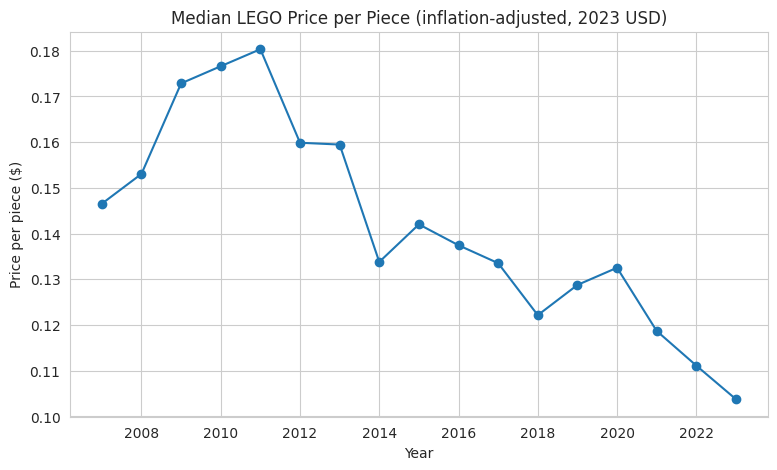

In [60]:
yearly = clean.groupby("year")["price_per_piece"].median()

plt.figure(figsize=(9, 5))
plt.plot(yearly.index, yearly.values, marker="o")
plt.title("Median LEGO Price per Piece (inflation-adjusted, 2023 USD)")
plt.xlabel("Year")
plt.ylabel("Price per piece ($)")
plt.savefig("chart1_price_per_piece.png", dpi=150, bbox_inches="tight")
plt.show()

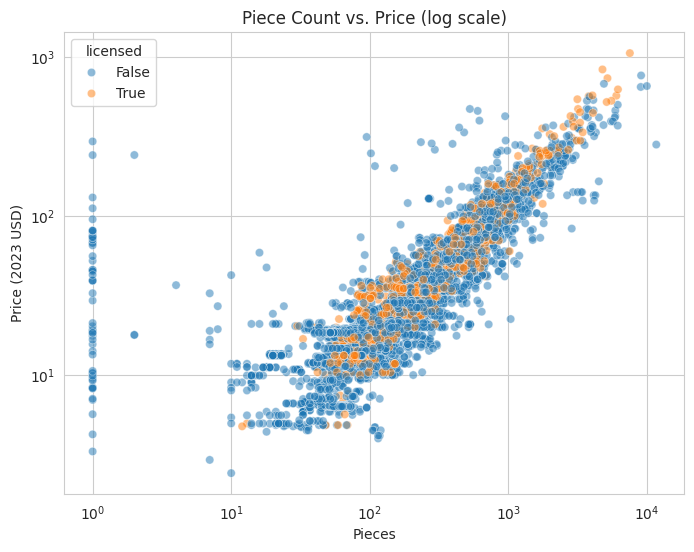

In [61]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=clean, x="pieces_final", y="price_real",
                hue="licensed", alpha=0.5)
plt.xscale("log")
plt.yscale("log")
plt.title("Piece Count vs. Price (log scale)")
plt.xlabel("Pieces")
plt.ylabel("Price (2023 USD)")
plt.savefig("chart2_pieces_vs_price.png", dpi=150, bbox_inches="tight")
plt.show()

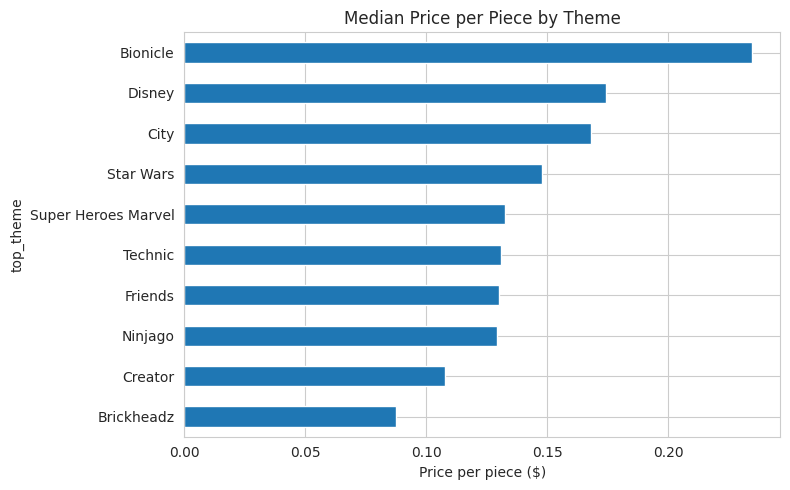

In [62]:
top10 = clean["top_theme"].value_counts().head(10).index
theme_ppp = (clean[clean["top_theme"].isin(top10)]
             .groupby("top_theme")["price_per_piece"].median()
             .sort_values())

plt.figure(figsize=(8, 5))
theme_ppp.plot(kind="barh")
plt.title("Median Price per Piece by Theme")
plt.xlabel("Price per piece ($)")
plt.tight_layout()
plt.savefig("chart3_theme_ppp.png", dpi=150, bbox_inches="tight")
plt.show()

year
2007    240.5
2008    235.5
2009    202.0
2010    192.5
2011    158.0
2012    208.0
2013    211.0
2014    225.0
2015    187.5
2016    183.5
2017    251.0
2018    224.0
2019    267.0
2020    234.0
2021    276.0
2022    369.0
2023    333.0
Name: pieces_final, dtype: float64
year
2007    0.120000
2008    0.115385
2009    0.098446
2010    0.225275
2011    0.153488
2012    0.187234
2013    0.151020
2014    0.200000
2015    0.175000
2016    0.166667
2017    0.254296
2018    0.254777
2019    0.321429
2020    0.237624
2021    0.179931
2022    0.286624
2023    0.249042
Name: licensed, dtype: float64


/tmp/ipykernel_576/3510246804.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ppp_size = clean.groupby(["year", "size"])["price_per_piece"].median().unstack()


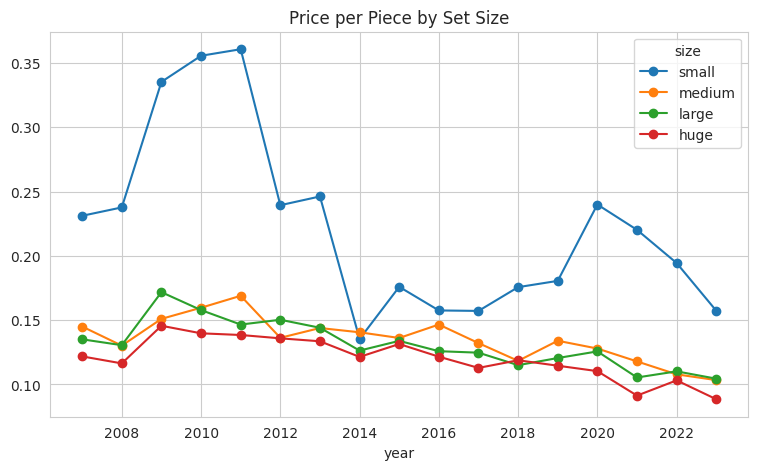

In [63]:
# Is the average set getting bigger?
print(clean.groupby("year")["pieces_final"].median())

# Is the licensed share changing?
print(clean.groupby("year")["licensed"].mean())

# Does the trend hold within size groups?
clean["size"] = pd.cut(clean["pieces_final"], [0, 100, 300, 800, 10000],
                       labels=["small", "medium", "large", "huge"])
ppp_size = clean.groupby(["year", "size"])["price_per_piece"].median().unstack()
ppp_size.plot(figsize=(9, 5), marker="o")
plt.title("Price per Piece by Set Size")
plt.savefig("chart4_size_groups.png", dpi=150, bbox_inches="tight")
plt.show()

In [53]:
import statsmodels.formula.api as smf
import numpy as np
model = smf.ols("np.log(price_real) ~ np.log(pieces_final) + year + licensed", data=clean).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     np.log(price_real)   R-squared:                       0.638
Model:                            OLS   Adj. R-squared:                  0.638
Method:                 Least Squares   F-statistic:                     2564.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:26:06   Log-Likelihood:                -3847.4
No. Observations:                4370   AIC:                             7703.
Df Residuals:                    4366   BIC:                             7728.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               46.8968 

In [54]:
# Keep themes with enough sets, group the rest as "Other"
top = clean["top_theme"].value_counts()
keep = top[top >= 50].index
clean["theme_grp"] = clean["top_theme"].where(clean["top_theme"].isin(keep), "Other")

clean["year_c"] = clean["year"] - 2007   # fixes the condition number warning

model2 = smf.ols(
    "np.log(price_real) ~ np.log(pieces_final) + year_c + C(theme_grp, Treatment('Other'))",
    data=clean
).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:     np.log(price_real)   R-squared:                       0.698
Model:                            OLS   Adj. R-squared:                  0.696
Method:                 Least Squares   F-statistic:                     386.1
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:26:06   Log-Likelihood:                -3450.6
No. Observations:                4370   AIC:                             6955.
Df Residuals:                    4343   BIC:                             7128.
Df Model:                          26                                         
Covariance Type:            nonrobust                                         
                                                              coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------

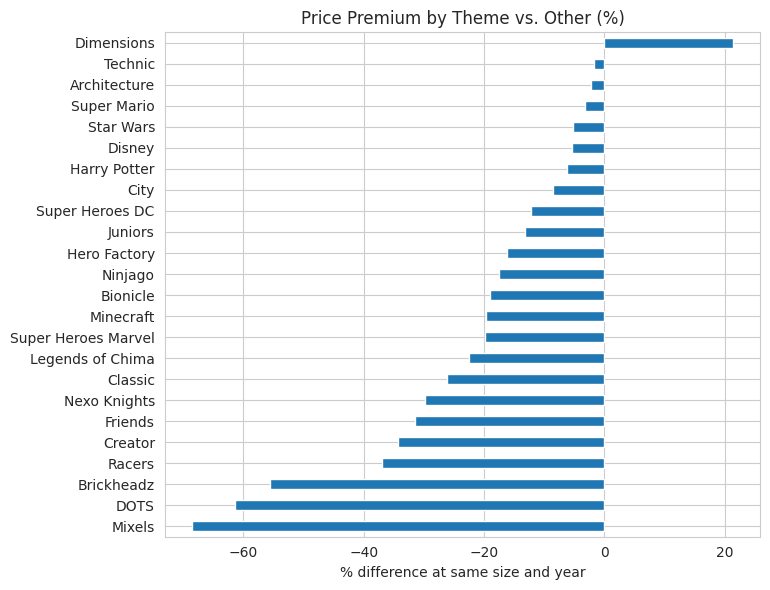

In [64]:
import numpy as np
coefs = model2.params.filter(like="theme_grp")
premium = (np.exp(coefs) - 1) * 100
premium.index = premium.index.str.extract(r"\[T\.(.*)\]")[0]
premium.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Price Premium by Theme vs. Other (%)")
plt.xlabel("% difference at same size and year")
plt.tight_layout()
plt.ylabel("")
plt.savefig("chart5_theme_premium.png", dpi=150, bbox_inches="tight")
plt.show()

In [67]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Features
X = clean[["pieces_final", "year_c", "licensed", "theme_grp"]].copy()
X["log_pieces"] = np.log(X["pieces_final"])
X["licensed"] = X["licensed"].astype(int)
X = pd.get_dummies(X.drop(columns="pieces_final"), columns=["theme_grp"])
y = np.log(clean["price_real"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Linear baseline
lr = LinearRegression().fit(X_train, y_train)

# Random forest
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                           random_state=42, n_jobs=-1).fit(X_train, y_train)

for name, m in [("Linear", lr), ("Random Forest", rf)]:
    pred = m.predict(X_test)
    print(name, "| R²:", round(r2_score(y_test, pred), 3),
          "| MAE ($):", round(mean_absolute_error(np.exp(y_test), np.exp(pred)), 2))

Linear | R²: 0.74 | MAE ($): 20.81
Random Forest | R²: 0.896 | MAE ($): 11.71


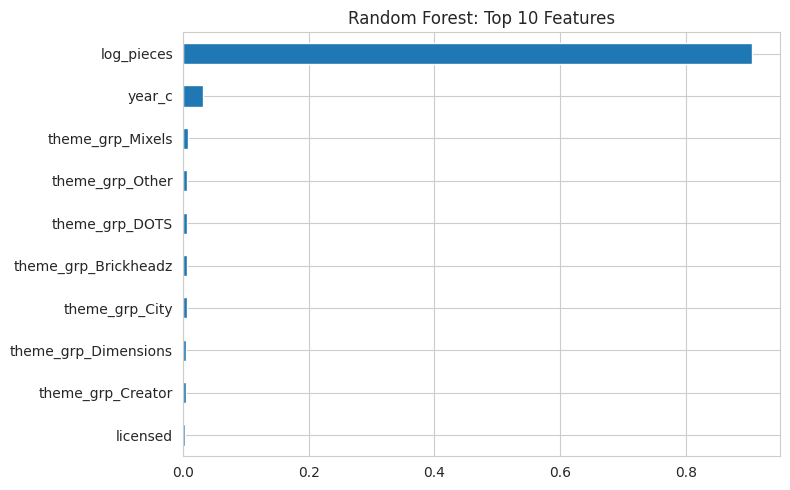

In [65]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest: Top 10 Features")
plt.tight_layout()
plt.savefig("chart6_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [66]:
!zip charts.zip *.png
from google.colab import files
files.download("charts.zip")

  adding: chart1_price_per_piece.png (deflated 11%)
  adding: chart2_pieces_vs_price.png (deflated 2%)
  adding: chart3_theme_ppp.png (deflated 22%)
  adding: chart4_size_groups.png (deflated 6%)
  adding: chart5_theme_premium.png (deflated 18%)
  adding: chart6_feature_importance.png (deflated 24%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>